# 02 — Exploratory Data Analysis

**Project:** Procurement Efficiency through Vendor KPI Development & Risk Analytics
**Data:** clean tables in `procurement_db` (MariaDB), produced in Phase 3 — 49,971 PO lines, 53,546 receipts, Jan 2023 – Dec 2025.

Goal: understand the shape of the data before defining KPIs — where the money goes, how long deliveries take,
who is late, who ships poor quality, and where stock is piling up. Aggregations are done in **SQL**; pandas and
matplotlib handle the rest. Charts are saved to `reports/figures/`.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

from sqlalchemy import text

from db import get_engine
from viz_style import BLUES, INK_2, MUTED, SERIES, apply_style, save, subtitle

apply_style()
engine = get_engine()


def q(sql, dates=()):
    df = pd.read_sql(text(sql), engine)  # text() escapes the % in DATE_FORMAT and LIKE
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df


pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Overview

In [2]:
q('''
SELECT COUNT(*)                      AS po_lines,
       COUNT(DISTINCT po_id)         AS purchase_orders,
       COUNT(DISTINCT vendor_id)     AS active_vendors,
       COUNT(DISTINCT item_id)       AS items_bought,
       MIN(order_date)               AS first_order,
       MAX(order_date)               AS last_order,
       ROUND(SUM(line_value) / 1e7, 1) AS spend_crore
FROM purchase_orders
''').T.rename(columns={0: "value"})

,value
po_lines,49971
purchase_orders,22707
active_vendors,150
items_bought,797
first_order,2023-01-02
last_order,2025-12-31
spend_crore,"1,540.00"


## 2. Spend over time

In [3]:
yearly = q('''
SELECT YEAR(order_date) AS year, COUNT(*) AS po_lines, SUM(line_value) / 1e7 AS spend_crore
FROM purchase_orders GROUP BY year ORDER BY year
''')
yearly["spend_growth_%"] = yearly.spend_crore.pct_change() * 100
yearly["lines_growth_%"] = yearly.po_lines.pct_change() * 100
yearly

,year,po_lines,spend_crore,spend_growth_%,lines_growth_%
0,2023,14774,416.56,NaN,NaN
1,2024,16940,530.07,27.25,14.66
2,2025,18257,593.41,11.95,7.77


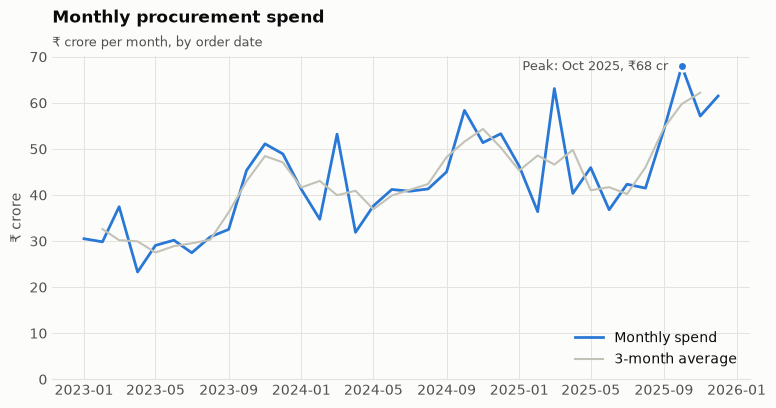

In [4]:
monthly = q('''
SELECT DATE_FORMAT(order_date, '%Y-%m-01') AS month, COUNT(*) AS po_lines, SUM(line_value) / 1e7 AS spend_crore
FROM purchase_orders GROUP BY month ORDER BY month
''', dates=["month"])

fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.spend_crore, color=SERIES[0], label="Monthly spend")
ax.plot(monthly.month, monthly.spend_crore.rolling(3, center=True).mean(), color=MUTED, lw=1.5,
        label="3-month average")
peak = monthly.loc[monthly.spend_crore.idxmax()]
ax.plot(peak.month, peak.spend_crore, "o", ms=7, color=SERIES[0], mec="white", mew=2)
ax.annotate(f"Peak: {peak.month:%b %Y}, ₹{peak.spend_crore:.0f} cr", (peak.month, peak.spend_crore),
            xytext=(-10, 0), textcoords="offset points", ha="right", va="center", color=INK_2, fontsize=9)
ax.legend(loc="lower right")
ax.set_title("Monthly procurement spend")
subtitle(ax, "₹ crore per month, by order date")
ax.set_ylim(0, None)
ax.set_ylabel("₹ crore")
save(fig, "01_monthly_spend")

,month_no,avg_lines,vs_average_%
0,1,"1,261.67",-9.11
1,2,"1,183.67",-14.73
2,3,"1,616.00",16.42
3,4,"1,139.33",-17.92
4,5,"1,348.00",-2.89
5,6,"1,167.00",-15.93
6,7,"1,170.33",-15.69
7,8,"1,245.67",-10.26
8,9,"1,408.67",1.48
9,10,"1,707.67",23.02


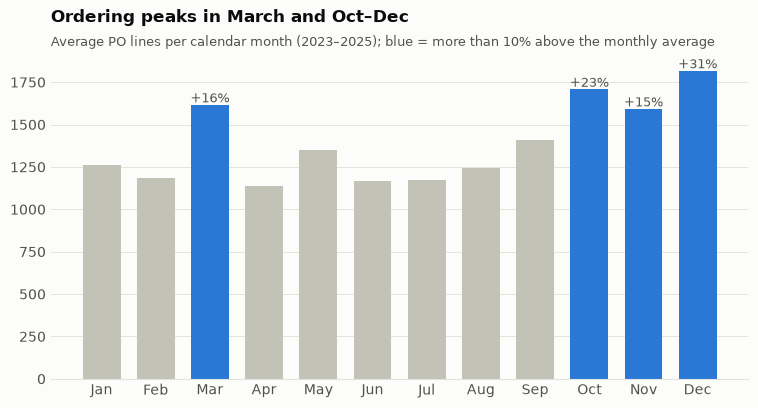

In [5]:
season = q('''
SELECT MONTH(order_date) AS month_no, COUNT(*) / COUNT(DISTINCT YEAR(order_date)) AS avg_lines
FROM purchase_orders GROUP BY month_no ORDER BY month_no
''')
season["vs_average_%"] = (season.avg_lines / season.avg_lines.mean() - 1) * 100
peaks = season["vs_average_%"] > 10
labels = pd.to_datetime(season.month_no.astype(str), format="%m").dt.strftime("%b")

fig, ax = plt.subplots()
ax.bar(labels, season.avg_lines, color=np.where(peaks, SERIES[0], MUTED), width=0.7)
for x, (v, pct, p) in enumerate(zip(season.avg_lines, season["vs_average_%"], peaks)):
    if p:
        ax.text(x, v + 15, f"+{pct:.0f}%", ha="center", color=INK_2, fontsize=9)
ax.set_title("Ordering peaks in March and Oct–Dec")
subtitle(ax, "Average PO lines per calendar month (2023–2025); blue = more than 10% above the monthly average")
ax.grid(axis="x", visible=False)
save(fig, "02_seasonality")
season

## 3. Where the money goes

,category,spend_crore,po_lines,vendors,share_%
6,Raw Materials,895.60,11087,30,58.15
5,Electrical & Electronics,201.40,8471,25,13.08
4,IT Hardware,172.70,2942,15,11.21
3,Packaging,90.67,7346,22,5.89
2,MRO,82.89,10927,28,5.38
1,Chemicals,79.97,5004,15,5.19
0,Office Supplies,16.81,4194,15,1.09


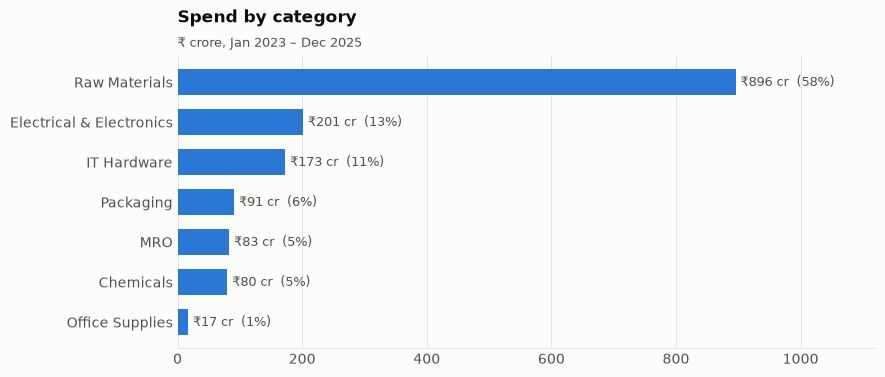

In [6]:
cat = q('''
SELECT i.category, SUM(p.line_value) / 1e7 AS spend_crore, COUNT(*) AS po_lines,
       COUNT(DISTINCT p.vendor_id) AS vendors
FROM purchase_orders p JOIN items i USING (item_id)
GROUP BY i.category ORDER BY spend_crore
''')
cat["share_%"] = cat.spend_crore / cat.spend_crore.sum() * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(cat.category, cat.spend_crore, color=SERIES[0], height=0.65)
for y, (v, s) in enumerate(zip(cat.spend_crore, cat["share_%"])):
    ax.text(v + 8, y, f"₹{v:,.0f} cr  ({s:.0f}%)", va="center", color=INK_2, fontsize=9)
ax.set_title("Spend by category")
subtitle(ax, "₹ crore, Jan 2023 – Dec 2025")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, cat.spend_crore.max() * 1.25)
save(fig, "03_spend_by_category")
cat.sort_values("spend_crore", ascending=False)

,vendor_id,vendor_name,category,state,cum_share,rank,spend_crore
0,V017,United Ispat LLP,Raw Materials,Tamil Nadu,18.74,1,288.64
1,V028,Sunrise Metals Pvt Ltd,Raw Materials,Haryana,26.31,2,116.55
2,V070,Patel Electronics & Co,Electrical & Electronics,Telangana,30.80,3,69.10
3,V016,Om Ispat Industries,Raw Materials,Gujarat,35.14,4,66.96
4,V106,Agarwal Systems Ltd,IT Hardware,Punjab,39.29,5,63.88
5,V025,Western Steel Industries,Raw Materials,Tamil Nadu,43.22,6,60.47
6,V026,Shah Iron & Steel Industries,Raw Materials,Madhya Pradesh,45.84,7,40.37
7,V007,Mehta Alloys Pvt Ltd,Raw Materials,Uttar Pradesh,47.93,8,32.16
8,V047,Modern Pack Solutions & Co,Packaging,West Bengal,49.81,9,28.90
9,V061,Pioneer Electricals Enterprises,Electrical & Electronics,Maharashtra,51.66,10,28.49


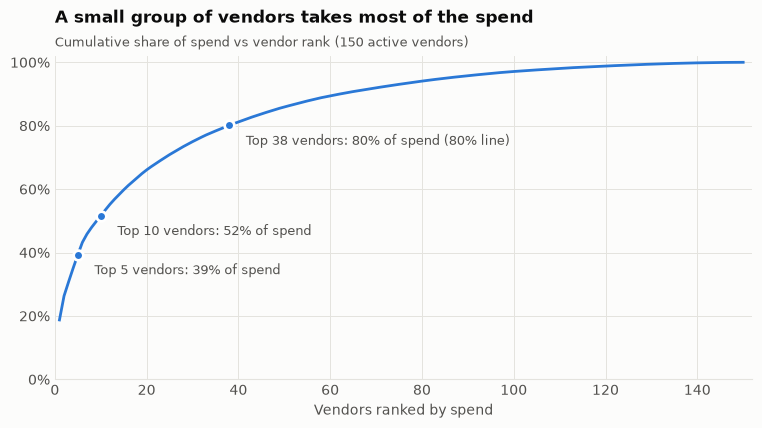

In [7]:
vend = q('''
SELECT v.vendor_id, v.vendor_name, v.category, v.state, SUM(p.line_value) AS spend
FROM purchase_orders p JOIN vendors v USING (vendor_id)
GROUP BY v.vendor_id, v.vendor_name, v.category, v.state
ORDER BY spend DESC
''')
vend["cum_share"] = vend.spend.cumsum() / vend.spend.sum() * 100
vend["rank"] = np.arange(1, len(vend) + 1)
n80 = int((vend.cum_share < 80).sum()) + 1

fig, ax = plt.subplots()
ax.plot(vend["rank"], vend.cum_share, color=SERIES[0])
for n in (5, 10, n80):
    y = vend.cum_share.iloc[n - 1]
    ax.plot(n, y, "o", ms=7, color=SERIES[0], mec="white", mew=2)
    label = f"Top {n} vendors: {y:.0f}% of spend" + (" (80% line)" if n == n80 else "")
    ax.annotate(label, (n, y), xytext=(12, -14), textcoords="offset points", color=INK_2, fontsize=9)
ax.set_title("A small group of vendors takes most of the spend")
subtitle(ax, f"Cumulative share of spend vs vendor rank ({len(vend)} active vendors)")
ax.set_xlabel("Vendors ranked by spend")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 102)
ax.set_xlim(0, len(vend) + 2)
save(fig, "04_vendor_pareto")
vend.head(10).assign(spend_crore=lambda d: d.spend / 1e7).drop(columns="spend")

In [8]:
single = q('''
WITH item_vendors AS (
    SELECT item_id, COUNT(DISTINCT vendor_id) AS n_vendors, SUM(line_value) AS spend
    FROM purchase_orders GROUP BY item_id
)
SELECT CASE WHEN n_vendors = 1 THEN '1 (single-source)' WHEN n_vendors = 2 THEN '2' ELSE '3+' END AS vendors_per_item,
       COUNT(*) AS items, SUM(spend) / 1e7 AS spend_crore
FROM item_vendors GROUP BY vendors_per_item ORDER BY vendors_per_item
''')
single["items_%"] = single["items"] / single["items"].sum() * 100
single["spend_%"] = single.spend_crore / single.spend_crore.sum() * 100
single

,vendors_per_item,items,spend_crore,items_%,spend_%
0,1 (single-source),151,111.50,18.95,7.24
1,2,226,397.69,28.36,25.82
2,3+,420,"1,030.86",52.70,66.94


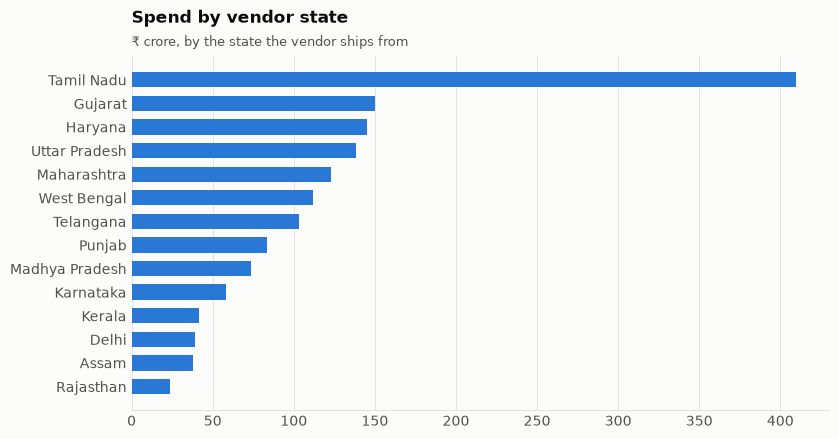

In [9]:
state = q('''
SELECT v.state, SUM(p.line_value) / 1e7 AS spend_crore, COUNT(DISTINCT v.vendor_id) AS vendors
FROM purchase_orders p JOIN vendors v USING (vendor_id)
GROUP BY v.state ORDER BY spend_crore
''')
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(state.state, state.spend_crore, color=SERIES[0], height=0.65)
ax.set_title("Spend by vendor state")
subtitle(ax, "₹ crore, by the state the vendor ships from")
ax.grid(axis="y", visible=False)
save(fig, "05_spend_by_state")

## 4. Order sizes, prices and lead times

In [10]:
lines = q('''
SELECT p.po_id, p.line_no, p.order_date, p.promised_date, p.order_type, p.quantity, p.unit_price, p.line_value,
       p.vendor_id, i.category, i.standard_price, v.state,
       r.first_received, r.last_received, r.qty_received, r.qty_rejected
FROM purchase_orders p
JOIN items i   USING (item_id)
JOIN vendors v USING (vendor_id)
LEFT JOIN (SELECT po_id, line_no, MIN(received_date) AS first_received, MAX(received_date) AS last_received,
                  SUM(qty_received) AS qty_received, SUM(qty_rejected) AS qty_rejected
           FROM deliveries GROUP BY po_id, line_no) r USING (po_id, line_no)
''', dates=["order_date", "promised_date", "first_received", "last_received"])
for c in ["unit_price", "line_value", "standard_price"]:
    lines[c] = lines[c].astype(float)
lines["lead_days"] = (lines.first_received - lines.order_date).dt.days
lines["delay_days"] = (lines.first_received - lines.promised_date).dt.days
lines["on_time"] = lines.delay_days <= 0
lines["price_index"] = lines.unit_price / lines.standard_price
delivered = lines.dropna(subset=["first_received"]).copy()
print(f"{len(lines):,} PO lines, {len(delivered):,} with at least one receipt, {len(lines) - len(delivered):,} still open")

49,971 PO lines, 49,080 with at least one receipt, 891 still open


count       49,971.00
mean       308,186.85
std        636,975.46
min          1,518.24
10%         24,849.84
50%        111,339.12
90%        690,457.60
99%      3,179,135.25
max     15,525,194.88
Name: line_value, dtype: float64

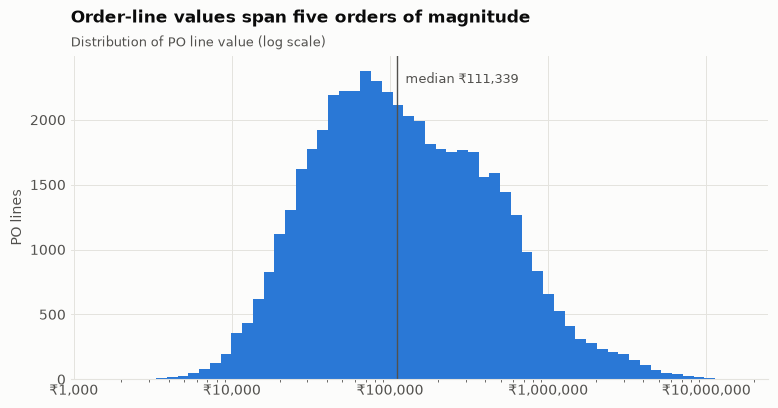

In [11]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(lines.line_value.min()), np.log10(lines.line_value.max()), 60)
ax.hist(lines.line_value, bins=bins, color=SERIES[0])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x:,.0f}"))
med = lines.line_value.median()
ax.axvline(med, color=INK_2, lw=1)
ax.text(med, ax.get_ylim()[1] * 0.95, f"  median ₹{med:,.0f}", color=INK_2, fontsize=9, va="top")
ax.set_title("Order-line values span five orders of magnitude")
subtitle(ax, "Distribution of PO line value (log scale)")
ax.set_ylabel("PO lines")
save(fig, "06_line_value_distribution")
lines.line_value.describe(percentiles=[.1, .5, .9, .99])

,mean,25%,50%,75%,max
category,,,,,
Chemicals,11.99,9.00,11.00,14.00,66.00
Electrical & Electronics,12.73,9.00,12.00,14.00,66.00
IT Hardware,21.22,15.00,19.00,23.00,109.00
MRO,10.07,5.00,7.00,11.00,104.00
Office Supplies,5.26,3.00,4.00,6.00,73.00
Packaging,13.00,7.00,10.00,15.00,97.00
Raw Materials,14.35,11.00,14.00,17.00,80.00


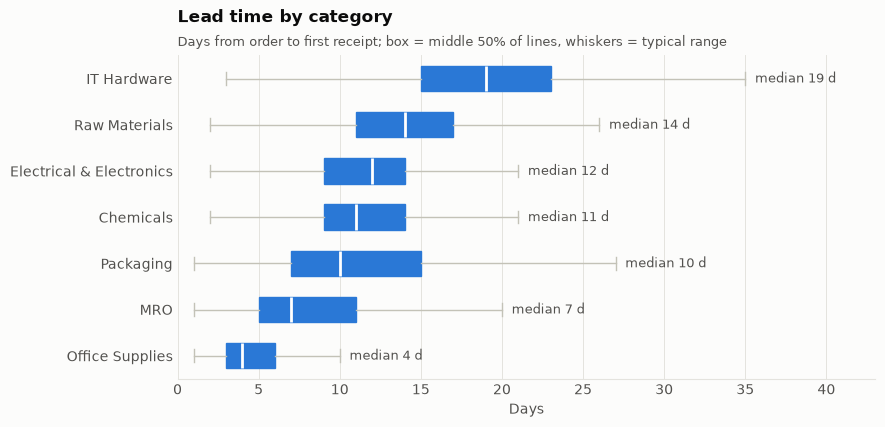

In [12]:
order = delivered.groupby("category").lead_days.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.2))
data = [delivered.loc[delivered.category == c, "lead_days"] for c in order]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=order, showfliers=False, patch_artist=True, widths=0.55,
                medianprops=dict(color="white", lw=2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for b in bp["boxes"]:
    b.set(facecolor=SERIES[0], edgecolor=SERIES[0])
for y, (d, cap) in enumerate(zip(data, bp["caps"][1::2]), start=1):
    ax.text(cap.get_xdata()[0] + 0.6, y, f"median {d.median():.0f} d", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, max(c.get_xdata()[0] for c in bp["caps"]) + 8)
ax.set_title("Lead time by category")
subtitle(ax, "Days from order to first receipt; box = middle 50% of lines, whiskers = typical range")
ax.set_xlabel("Days")
ax.grid(axis="y", visible=False)
save(fig, "07_lead_time_by_category")
delivered.groupby("category").lead_days.describe()[["mean", "25%", "50%", "75%", "max"]]

order_date,2023,2024,2025
order_type,,,
Bulk,0.91,0.95,0.99
Regular,1.04,1.09,1.15
Urgent,1.14,1.20,1.27


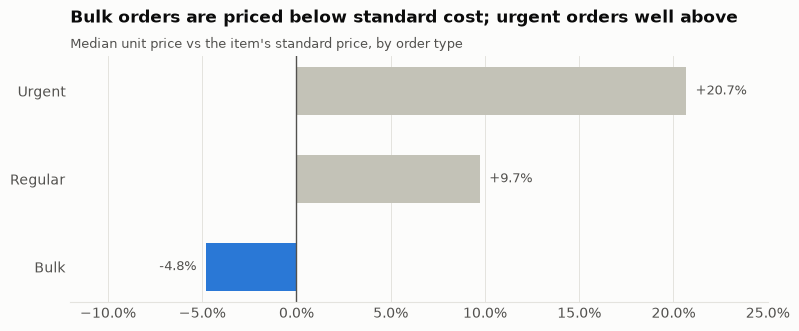

In [13]:
pi = lines.groupby("order_type").price_index.median().reindex(["Bulk", "Regular", "Urgent"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(pi.index, (pi - 1) * 100, color=[SERIES[0] if v < 1 else MUTED for v in pi], height=0.55)
for y, v in enumerate(pi):
    ax.text((v - 1) * 100 + (0.5 if v >= 1 else -0.5), y, f"{(v - 1) * 100:+.1f}%", va="center",
            ha="left" if v >= 1 else "right", color=INK_2, fontsize=9)
ax.axvline(0, color=INK_2, lw=1)
ax.set_title("Bulk orders are priced below standard cost; urgent orders well above")
subtitle(ax, "Median unit price vs the item's standard price, by order type")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_xlim(-12, 25)
save(fig, "08_price_by_order_type")
by_year = lines.pivot_table(index="order_type", columns=lines.order_date.dt.year, values="price_index", aggfunc="median")
by_year

In [14]:
# Like-for-like: same item, same vendor, same quarter -> bulk vs regular unit price
paired =(q('SELECT item_id, vendor_id, order_date, order_type, unit_price FROM purchase_orders', dates=["order_date"])
          .assign(quarter=lambda d: d.order_date.dt.to_period("Q"), unit_price=lambda d: d.unit_price.astype(float)))
paired = (paired[paired.order_type.isin(["Bulk", "Regular"])]
          .groupby(["item_id", "vendor_id", "quarter", "order_type"]).unit_price.median().unstack().dropna())
discount = (1 - paired.Bulk / paired.Regular) * 100
print(f"{len(paired):,} item-vendor-quarter groups with both bulk and regular orders")
print(f"Bulk discount vs regular, like-for-like: median {discount.median():.1f}%, middle 50% {discount.quantile(.25):.1f}–{discount.quantile(.75):.1f}%")

4,358 item-vendor-quarter groups with both bulk and regular orders
Bulk discount vs regular, like-for-like: median 13.1%, middle 50% 10.7–15.4%


## 5. Delivery performance — first look

*On time* here = the first receipt arrived on or before the promised date. Phase 5 will refine this
(e.g. on-time **and** in full).

**Watch out for right-censoring:** at the 31 Dec 2025 cut-off, lines that are going to be late simply haven't
arrived yet. Measuring on-time only over *delivered* lines therefore makes the last weeks look far better than they
are (late arrivals are missing). The fix: judge every line whose promised date has passed, and count a line that is
past its promised date with nothing received as **late**. Lines promised after the cut-off are not yet due and are left out.

Lines due by the cut-off: 49,310 (of which 289 not yet received -> late)
On-time (first receipt by promised date): 71.0%
Same metric over delivered lines only (biased upward): 71.4%
Late deliveries received: 14,021; median delay 7 days, 90th percentile 23 days


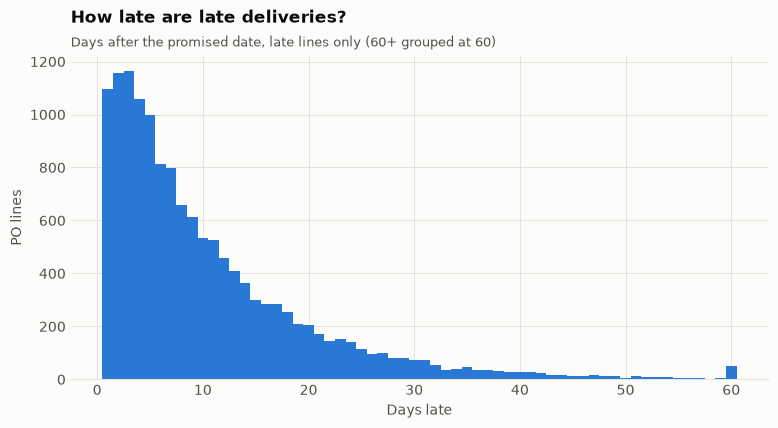

In [15]:
CUTOFF = pd.Timestamp("2025-12-31")
due = lines[lines.promised_date <= CUTOFF].copy()
open_late = due.first_received.isna().sum()
print(f"Lines due by the cut-off: {len(due):,} (of which {open_late:,} not yet received -> late)")
print(f"On-time (first receipt by promised date): {due.on_time.mean():.1%}")
print(f"Same metric over delivered lines only (biased upward): {delivered[delivered.promised_date <= CUTOFF].on_time.mean():.1%}")
late = due[~due.on_time & due.first_received.notna()]
print(f"Late deliveries received: {len(late):,}; median delay {late.delay_days.median():.0f} days, 90th percentile {late.delay_days.quantile(.9):.0f} days")

fig, ax = plt.subplots()
ax.hist(late.delay_days.clip(upper=60), bins=np.arange(0.5, 61.5, 1), color=SERIES[0])
ax.set_title("How late are late deliveries?")
subtitle(ax, "Days after the promised date, late lines only (60+ grouped at 60)")
ax.set_xlabel("Days late")
ax.set_ylabel("PO lines")
save(fig, "09_delay_distribution")

,Jun–Sep late-rate increase (pp)
state,
Assam,16.61
West Bengal,15.87
Maharashtra,15.31
Kerala,13.98
Delhi,4.91
Gujarat,3.64
Madhya Pradesh,1.22
Punjab,1.02
Tamil Nadu,0.93


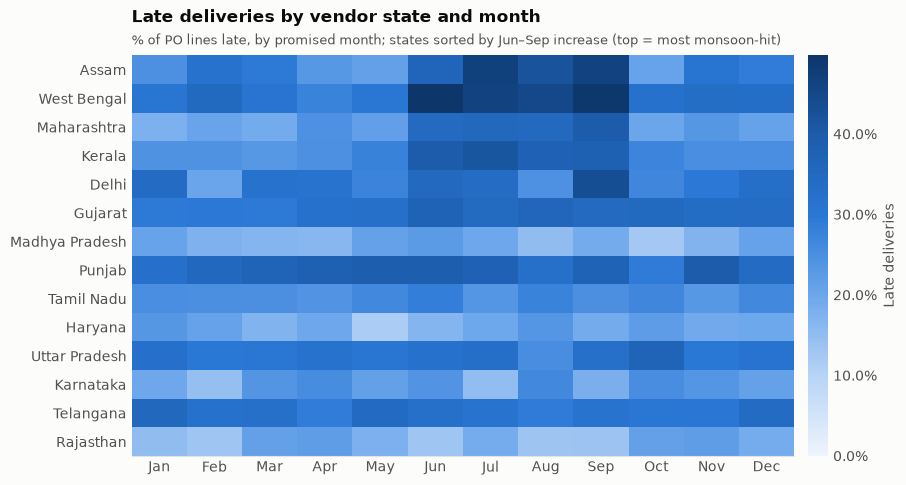

In [16]:
due["month_no"] = due.promised_date.dt.month
heat = due.pivot_table(index="state", columns="month_no", values="on_time", aggfunc="mean")
late_rate = (1 - heat) * 100
monsoon = late_rate[[6, 7, 8, 9]].mean(axis=1) - late_rate.drop(columns=[6, 7, 8, 9]).mean(axis=1)
late_rate = late_rate.loc[monsoon.sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5.2))
im = ax.imshow(late_rate.values, cmap=BLUES, aspect="auto", vmin=0, vmax=late_rate.values.max())
ax.set_xticks(range(12), pd.date_range("2025-01-01", periods=12, freq="MS").strftime("%b"))
ax.set_yticks(range(len(late_rate)), late_rate.index)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=mtick.PercentFormatter())
cb.outline.set_visible(False)
cb.set_label("Late deliveries", color=INK_2)
ax.set_title("Late deliveries by vendor state and month")
subtitle(ax, "% of PO lines late, by promised month; states sorted by Jun–Sep increase (top = most monsoon-hit)")
save(fig, "10_late_rate_state_month")
monsoon.sort_values(ascending=False).rename("Jun–Sep late-rate increase (pp)").to_frame()

States whose late rate rises > 10 pp in Jun–Sep: ['Assam', 'Kerala', 'Maharashtra', 'West Bengal']


group,"Monsoon-hit states (Assam, Kerala, Maharashtra, West Bengal)",Other states
promised_date,,
2025-10-01,72.74,72.45
2025-11-01,71.35,71.55
2025-12-01,72.00,72.85


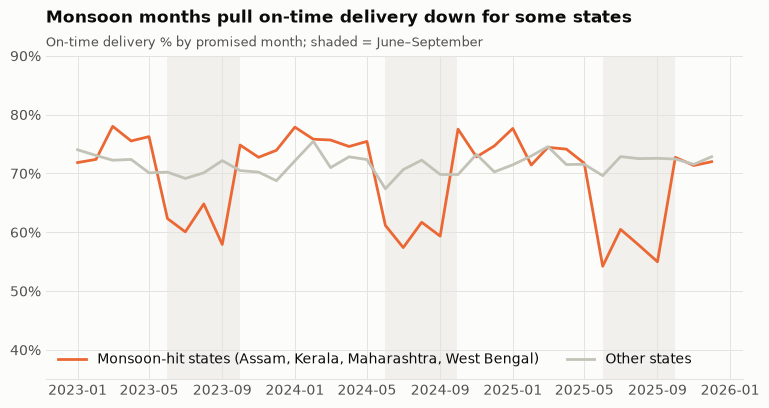

In [17]:
hit = monsoon[monsoon > 10].index.tolist()
print("States whose late rate rises > 10 pp in Jun–Sep:", hit)
due["group"] = np.where(due.state.isin(hit), "Monsoon-hit states (" + ", ".join(sorted(hit)) + ")", "Other states")
m = due.groupby([due.promised_date.dt.to_period("M"), "group"]).on_time.mean().unstack() * 100
m.index = m.index.to_timestamp()

fig, ax = plt.subplots()
for g in m.columns:
    ax.plot(m.index, m[g], color=MUTED if g == "Other states" else SERIES[1], label=g)
for y in (2023, 2024, 2025):
    ax.axvspan(pd.Timestamp(f"{y}-06-01"), pd.Timestamp(f"{y}-09-30"), color="#f1f0ec", lw=0, zorder=0)
ax.set_title("Monsoon months pull on-time delivery down for some states")
subtitle(ax, "On-time delivery % by promised month; shaded = June–September")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(35, 90)
ax.legend(loc="lower left", ncol=2)
save(fig, "11_monsoon_on_time")
m.tail(3)

year,2023,2024,2025,change
vendor_id,,,,
V034,74.60,80.39,47.71,-32.69
V079,74.82,79.58,54.70,-24.89
V014,91.49,92.79,69.37,-23.42
V118,69.09,63.04,39.76,-23.28
V094,76.92,93.75,77.08,-16.67


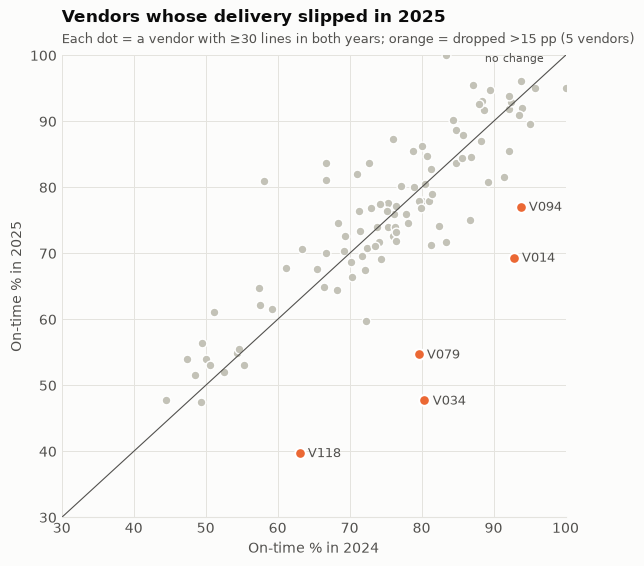

In [18]:
vy = (due.assign(year=due.order_date.dt.year)
      .groupby(["vendor_id", "year"]).agg(on_time=("on_time", "mean"), n=("on_time", "size")).reset_index())
wide = vy[vy.n >= 30].pivot(index="vendor_id", columns="year", values="on_time").dropna(subset=[2024, 2025]) * 100
wide["change"] = wide[2025] - wide[2024]
drop = wide.change < -15

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(wide.loc[~drop, 2024], wide.loc[~drop, 2025], s=40, color=MUTED, edgecolor="white", lw=1)
ax.scatter(wide.loc[drop, 2024], wide.loc[drop, 2025], s=60, color=SERIES[1], edgecolor="white", lw=1.5)
for vid, r in wide[drop].iterrows():
    ax.annotate(vid, (r[2024], r[2025]), xytext=(6, -3), textcoords="offset points", color=INK_2, fontsize=9)
ax.plot([30, 100], [30, 100], color=INK_2, lw=0.8)
ax.text(97, 99, "no change", color=INK_2, fontsize=8, ha="right")
ax.set(xlim=(30, 100), ylim=(30, 100), xlabel="On-time % in 2024", ylabel="On-time % in 2025")
ax.set_title("Vendors whose delivery slipped in 2025")
subtitle(ax, f"Each dot = a vendor with ≥30 lines in both years; orange = dropped >15 pp ({drop.sum()} vendors)")
save(fig, "12_vendor_on_time_2024_vs_2025")
wide[drop].sort_values("change")

Vendors below 65% on-time: 27 of 148


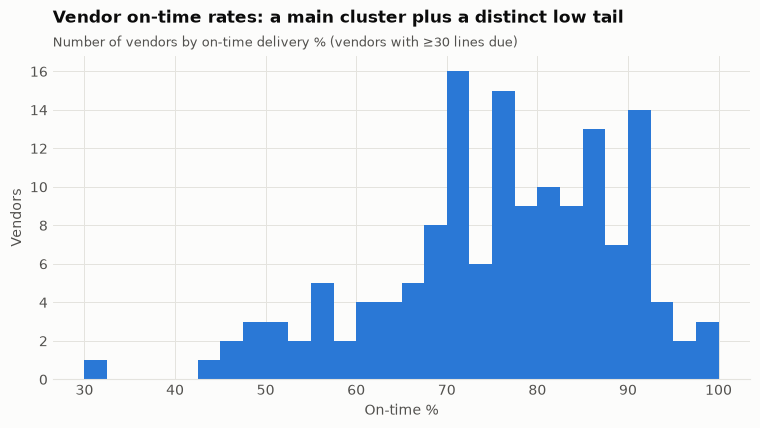

In [19]:
vendor_otd = due.groupby("vendor_id").agg(on_time=("on_time", "mean"), lines=("on_time", "size"))
vendor_otd = vendor_otd[vendor_otd.lines >= 30]
fig, ax = plt.subplots()
ax.hist(vendor_otd.on_time * 100, bins=np.arange(30, 101, 2.5), color=SERIES[0])
ax.set_title("Vendor on-time rates: a main cluster plus a distinct low tail")
subtitle(ax, "Number of vendors by on-time delivery % (vendors with ≥30 lines due)")
ax.set_xlabel("On-time %")
ax.set_ylabel("Vendors")
save(fig, "13_vendor_on_time_distribution")
print(f"Vendors below 65% on-time: {(vendor_otd.on_time < .65).sum()} of {len(vendor_otd)}")

## 6. Quality — rejections at goods receipt

Overall rejection rate: 0.35% of received quantity


,vendor_id,rejected,received,receipts_with_rejection,receipts,rejection_rate_%,receipts_hit_%
109,V110,72.00,"2,489.00",20.00,57,2.89,35.09
60,V061,"3,762.00","153,112.00",325.00,1336,2.46,24.33
91,V092,543.00,"17,330.00",23.00,99,3.13,23.23
88,V089,481.00,"19,128.00",13.00,59,2.51,22.03
149,V150,"1,882.00","78,326.00",21.00,109,2.40,19.27
67,V068,277.00,"15,748.00",32.00,203,1.76,15.76
50,V051,"1,333.00","503,512.00",22.00,150,0.26,14.67
32,V033,"7,651.00","789,385.00",12.00,93,0.97,12.90
56,V057,194.00,"32,063.00",30.00,235,0.61,12.77
73,V074,419.00,"16,837.00",9.00,85,2.49,10.59


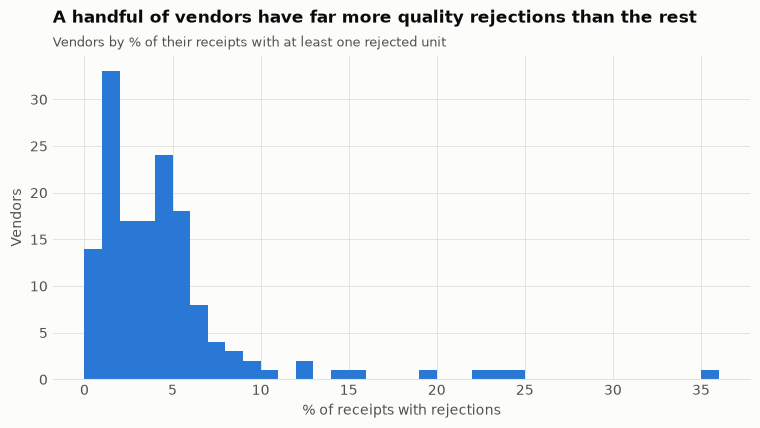

In [20]:
rej = q('''
SELECT p.vendor_id, SUM(d.qty_rejected) AS rejected, SUM(d.qty_received) AS received,
       SUM(d.qty_rejected > 0) AS receipts_with_rejection, COUNT(*) AS receipts
FROM deliveries d JOIN purchase_orders p USING (po_id, line_no)
WHERE d.qty_rejected IS NOT NULL
GROUP BY p.vendor_id
''')
rej["rejection_rate_%"] = rej.rejected / rej.received * 100
rej["receipts_hit_%"] = rej.receipts_with_rejection / rej.receipts * 100
print(f"Overall rejection rate: {rej.rejected.sum() / rej.received.sum():.2%} of received quantity")

fig, ax = plt.subplots()
ax.hist(rej["receipts_hit_%"], bins=np.arange(0, rej["receipts_hit_%"].max() + 1.5, 1), color=SERIES[0])
ax.set_title("A handful of vendors have far more quality rejections than the rest")
subtitle(ax, "Vendors by % of their receipts with at least one rejected unit")
ax.set_xlabel("% of receipts with rejections")
ax.set_ylabel("Vendors")
save(fig, "14_vendor_rejection_distribution")
rej.sort_values("receipts_hit_%", ascending=False).head(12)

## 7. Inventory — where stock is piling up

In [21]:
inv = q('''
SELECT i.item_id, i.item_name, i.category, i.standard_price,
       o.qty_on_hand AS opening_qty, c.qty_on_hand AS closing_qty,
       s.avg_monthly_sales_h2_2025, s.sold_2025, s.sold_2023
FROM items i
JOIN inventory o ON o.item_id = i.item_id AND o.snapshot_date = '2022-12-31'
JOIN inventory c ON c.item_id = i.item_id AND c.snapshot_date = '2025-12-31'
JOIN (SELECT item_id,
             AVG(CASE WHEN month >= '2025-07-01' THEN qty_sold END) AS avg_monthly_sales_h2_2025,
             SUM(CASE WHEN YEAR(month) = 2025 THEN qty_sold END)     AS sold_2025,
             SUM(CASE WHEN YEAR(month) = 2023 THEN qty_sold END)     AS sold_2023
      FROM sales GROUP BY item_id) s ON s.item_id = i.item_id
''')
for c in ["standard_price", "avg_monthly_sales_h2_2025"]:
    inv[c] = inv[c].astype(float)
inv["closing_value_cr"] = inv.closing_qty * inv.standard_price / 1e7
inv["months_of_cover"] = inv.closing_qty / inv.avg_monthly_sales_h2_2025.replace(0, np.nan)
inv["sales_change_%"] = (inv.sold_2025 / inv.sold_2023.replace(0, np.nan) - 1) * 100
print(f"Closing stock value (at standard cost): ₹{inv.closing_value_cr.sum():,.1f} crore across {len(inv)} items")
print(f"Items with no sales in H2 2025 (dead stock): {inv.months_of_cover.isna().sum()}")
inv.months_of_cover.describe(percentiles=[.25, .5, .75, .9])

Closing stock value (at standard cost): ₹228.5 crore across 800 items
Items with no sales in H2 2025 (dead stock): 7


count   793.00
mean      8.57
std      13.00
min       0.00
25%       2.24
50%       3.04
75%       4.19
90%      28.52
max      68.00
Name: months_of_cover, dtype: float64

Items with > 6 months of cover: 167 (21%), holding ₹127.9 crore (56% of stock value)


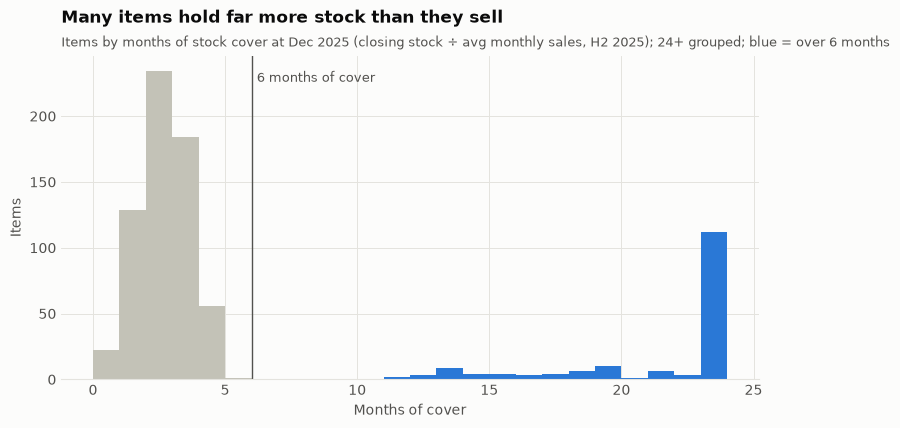

In [22]:
cover = inv.months_of_cover.dropna().clip(upper=24)
fig, ax = plt.subplots()
n, edges, patches = ax.hist(cover, bins=np.arange(0, 25, 1), color=SERIES[0])
for p, left in zip(patches, edges[:-1]):
    if left < 6:
        p.set_facecolor(MUTED)
ax.axvline(6, color=INK_2, lw=1)
ax.text(6.2, ax.get_ylim()[1] * 0.92, "6 months of cover", color=INK_2, fontsize=9)
ax.set_title("Many items hold far more stock than they sell")
subtitle(ax, "Items by months of stock cover at Dec 2025 (closing stock ÷ avg monthly sales, H2 2025); 24+ grouped; blue = over 6 months")
ax.set_xlabel("Months of cover")
ax.set_ylabel("Items")
save(fig, "15_months_of_cover")
over = inv[inv.months_of_cover > 6]
print(f"Items with > 6 months of cover: {len(over)} ({len(over) / len(inv):.0%}), holding ₹{over.closing_value_cr.sum():,.1f} crore "
      f"({over.closing_value_cr.sum() / inv.closing_value_cr.sum():.0%} of stock value)")

In [23]:
by_cat = inv.assign(over=inv.months_of_cover > 6).groupby("category").agg(
    stock_value_cr=("closing_value_cr", "sum"),
    items=("item_id", "size"),
    items_over_6m=("over", "sum"),
    median_cover_months=("months_of_cover", "median"),
).sort_values("stock_value_cr", ascending=False)
by_cat

,stock_value_cr,items,items_over_6m,median_cover_months
category,,,,
Raw Materials,131.71,140,34,3.20
Electrical & Electronics,29.98,140,27,3.07
IT Hardware,26.44,70,13,2.98
Packaging,14.63,120,24,2.81
Chemicals,12.90,90,21,3.11
MRO,10.24,160,27,2.92
Office Supplies,2.64,80,21,3.17


## 8. How much of the analysis rests on fixed or imputed data?

In [24]:
dq = q('''
SELECT CASE WHEN dq_flags IS NULL THEN 'untouched'
            WHEN dq_flags LIKE '%imputed%' THEN 'contains an imputed value'
            ELSE 'fixed (format / ID / sign / x100)' END AS status,
       COUNT(*) AS po_lines, SUM(line_value) / 1e7 AS spend_crore
FROM purchase_orders GROUP BY status
''')
dq["lines_%"] = dq.po_lines / dq.po_lines.sum() * 100
dq["spend_%"] = dq.spend_crore / dq.spend_crore.sum() * 100
dq

,status,po_lines,spend_crore,lines_%,spend_%
0,contains an imputed value,1127,34.65,2.26,2.25
1,fixed (format / ID / sign / x100),2131,70.82,4.26,4.60
2,untouched,46713,"1,434.57",93.48,93.15


## 9. Summary

The full write-up, with figure references and the KPI design decisions that follow from it, is in
[`reports/eda_findings.md`](../reports/eda_findings.md). In short:

1. Spend is rising faster than volume (+27% / +12% vs +15% / +8%), driven by price inflation.
2. Orders peak in March and October–December.
3. Spend is concentrated: one vendor holds 18.7%, the top 10 hold 52%, and Raw Materials is 58%.
4. Bulk orders are about 13% cheaper like-for-like; urgent orders cost about 10 points more.
5. On-time delivery is 71%. Four states lose 14–17 points every monsoon, 27 vendors are below 65%, and 5 vendors slipped sharply in 2025.
6. Rejections are concentrated in about 9 vendors.
7. 21% of items hold 56% of stock value, with more than 6 months of cover.